# Phase 3, Step 1: Data preparation

**What this notebook does:** it loads the three public datasets (4G, 5G and the network operator data), cleans them, splits every trace into **train / validation / test** in time order, scales the numbers, and saves the result to Google Drive. The models in the next steps will read what is saved here.

**How to use it:** run the cells from top to bottom (Runtime > Run all). Each cell has a short note above it saying what it does and what you should see.

## 1. Setup
Connects to Google Drive, loads the libraries, and holds **all the settings in one place**: folder locations, which columns to use, the window size (12 steps) and the split (70% train, 10% validation, 20% test). If a setting ever needs changing, change it here only.

**You should see:** the 5G folder path and the 4G folder path (it should not say NOT FOUND).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ======================= SETTINGS =======================
ROOT     = "/content/drive/MyDrive/dtn_project"
PATH_5G  = f"{ROOT}/5G-production-dataset/5G-production-dataset"
FEATS    = ["DL_bitrate","UL_bitrate","RSRP","RSRQ","SNR","CQI","Speed"]  # first = forecast target
TIME_FMT = "%Y.%m.%d_%H.%M.%S"
WINDOW, MAX_GAP, MIN_LEN = 12, 5, 300     # input steps, max gap to fill (s), min trace length (s)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.10         # test = remaining 20%
BOUNDS = {"DL_bitrate":(0,None), "UL_bitrate":(0,None), "CQI":(0,15),
          "RSRP":(-140,-40), "RSRQ":(-40,0)}   # only impossible values are clipped
# ========================================================

cands = [d for d in glob.glob("/content/drive/MyDrive/**/LTE_Dataset", recursive=True)
         if "__MACOSX" not in d]
PATH_4G = None
if cands:
    PATH_4G = cands[0] + "/Dataset" if os.path.isdir(cands[0] + "/Dataset") else cands[0]
print("5G folder:", PATH_5G)
print("4G folder:", PATH_4G or "NOT FOUND")
os.makedirs(f"{ROOT}/processed", exist_ok=True)

Mounted at /content/drive
5G folder: /content/drive/MyDrive/dtn_project/5G-production-dataset/5G-production-dataset
4G folder: /content/drive/MyDrive/dtn_project/LTE_Dataset/Dataset


## 2. Helper functions
Defines the tools used by the later cells. **Nothing is processed here**, it only defines them.
- `read_trace`: opens one file, fixes the timestamps, fills small gaps (up to 5 seconds), and keeps the longest gap-free stretch.
- `split`: cuts a trace into train / validation / test, in time order, with no shuffling.
- `process`: does all of this for every file in a dataset, scales the numbers (using the **train part only**), and saves the result to Drive.
- `make_windows`: cuts a series into windows of 12 steps, each one used to predict the next value.

**You should see:** `Functions ready`

In [2]:
def list_csvs(root):
    return sorted(f for f in glob.glob(f"{root}/**/*.csv", recursive=True)
                  if "__MACOSX" not in f and not os.path.basename(f).startswith("._"))

def read_trace(path):
    df = pd.read_csv(path, na_values=["-", " ", ""])
    df.columns = [c.strip() for c in df.columns]
    miss = [c for c in FEATS if c not in df.columns]
    if miss or "Timestamp" not in df.columns:
        return None, f"missing columns {miss}", False
    ts = pd.to_datetime(df["Timestamp"], format=TIME_FMT, errors="coerce")
    bad_ts = ts.isna().mean() > 0.5
    if bad_ts:                                    # fallback: assume 1 s steps
        ts = pd.Timestamp("2000-01-01") + pd.to_timedelta(range(len(df)), unit="s")
    df.index = ts
    df = df[df.index.notna()]
    df = df[~df.index.duplicated()].sort_index()
    df = df[FEATS].apply(pd.to_numeric, errors="coerce")
    for c, (lo, hi) in BOUNDS.items():
        if c in df: df[c] = df[c].clip(lo, hi)
    df = df.resample("1s").mean().interpolate(limit=MAX_GAP, limit_area="inside")
    ok = df.notna().all(axis=1)
    grp = (ok != ok.shift()).cumsum()
    best = max((g for _, g in df[ok].groupby(grp[ok])), key=len, default=None)
    if best is None or len(best) < MIN_LEN:
        return None, "no clean stretch long enough", bad_ts
    return best, "", bad_ts            # longest gap-free stretch of the trace

def split(a):
    n = len(a); i = int(n * TRAIN_FRAC); j = int(n * (TRAIN_FRAC + VAL_FRAC))
    return a[:i], a[i:j], a[j:]        # time order, no shuffling

def process(name, root):
    out = f"{ROOT}/processed/{name}"; os.makedirs(out, exist_ok=True)
    for f in glob.glob(out + "/*.npz"): os.remove(f)          # clean re-runs
    traces, dropped, bad = {}, {}, 0
    for p in list_csvs(root):
        d, why, bt = read_trace(p); bad += bt
        key = os.path.relpath(p, root)[:-4].replace(os.sep, "__")
        if d is None: dropped[key] = why
        else: traces[key] = d
    if not traces:
        raise RuntimeError(f"No usable traces for {name}: {dropped}")
    tr_all = np.vstack([split(d.values)[0] for d in traces.values()])
    mu, sd = tr_all.mean(0), tr_all.std(0) + 1e-8             # scaler fitted on TRAIN only
    rows = []
    for k, d in traces.items():
        a, b, c = [((x - mu) / sd).astype("float32") for x in split(d.values)]
        np.savez(f"{out}/{k}.npz", train=a, val=b, test=c)
        rows.append(dict(trace=k, steps=len(d), train=len(a), val=len(b), test=len(c)))
    json.dump(dict(cols=FEATS, mean=mu.tolist(), std=sd.tolist(), window=WINDOW,
                   split=[TRAIN_FRAC, VAL_FRAC]), open(f"{out}/scaler.json", "w"))
    summ = pd.DataFrame(rows); summ.to_csv(f"{out}/summary.csv", index=False)
    print(f"{name}: kept {len(traces)} | dropped {len(dropped)} | timestamp fallback {bad}")
    for k, why in list(dropped.items())[:5]: print("   dropped:", k, "->", why)
    return summ

def make_windows(arr, window=WINDOW, target_idx=0, context=None):
    """context = end of the previous split, so val/test don't lose their first steps."""
    if context is not None: arr = np.vstack([context[-window:], arr])
    w = np.lib.stride_tricks.sliding_window_view(arr, (window, arr.shape[1]))[:-1, 0]
    return w, arr[window:, target_idx]
print("Functions ready")

Functions ready


## 3. Process the 4G and 5G data
Runs `process` three times:
- **`5g`**: all 7 signals (downlink, uplink, RSRP, RSRQ, SNR, CQI, speed).
- **`4g`**: 5 signals, **without SNR and CQI**, because about 25% of their values are missing in the 4G data. This keeps almost every trace.
- **`4g_full`**: all 7 signals, but only for the traces that have SNR and CQI. It is used later only to test whether those two signals help.

Traces with less than 300 seconds of clean data are dropped.

In [3]:
import hashlib
SUMM = {}
SUMM["5g"] = process("5g", PATH_5G)

FULL = FEATS
FEATS = ["DL_bitrate", "UL_bitrate", "RSRP", "RSRQ", "Speed"]     # no SNR/CQI (about 25% missing in 4G)
SUMM["4g"] = process("4g", PATH_4G)                               # main 4G set: nearly all traces
FEATS = FULL
SUMM["4g_full"] = process("4g_full", PATH_4G)                     # with SNR + CQI: for the extra-signal ablation only

5g: kept 79 | dropped 4 | timestamp fallback 0
   dropped: Amazon_Prime__Driving__Season3-TheExpanse__B_2019.12.02_09.39.35 -> no clean stretch long enough
   dropped: Download__Driving__B_2019.12.16_11.49.59 -> no clean stretch long enough
   dropped: Download__Driving__B_2020.02.27_17.30.15 -> no clean stretch long enough
   dropped: Netflix__Driving__animated-RickandMorty__B_2019.11.21_10.20.17 -> no clean stretch long enough
4g: kept 134 | dropped 1 | timestamp fallback 0
   dropped: train__A_2018.02.02_10.28.45 -> no clean stretch long enough
4g_full: kept 108 | dropped 27 | timestamp fallback 0
   dropped: bus__A_2018.01.25_16.33.53 -> no clean stretch long enough
   dropped: bus__A_2018.01.26_11.26.26 -> no clean stretch long enough
   dropped: bus__B_2018.01.25_19.50.43 -> no clean stretch long enough
   dropped: car__A_2017.12.05_07.24.29 -> no clean stretch long enough
   dropped: car__A_2017.12.06_13.01.21 -> no clean stretch long enough


## 4. Process the operator data
The operator data is different: plain text files, one value every 5 minutes. This cell reads every series from both folders (`data_series` and `data_real`) and notes the type of each one (internet, sessions, VPN, downstream).

Because the time in these files starts at 0 (no real clock time), the cell adds **two columns for the position inside the day** (288 steps = 1 day). Only the value itself is scaled. Series shorter than 7 days are dropped.

In [4]:
# ---------------- operator settings ----------------
OP_ROOT = f"{ROOT}/network_operator_KPIs_time_series_dataset/network_operator_KPIs_time_series_dataset"
OP_DIRS = ["data_series", "data_real"]     # all series from both folders
STEP, DAY = 300, 288                       # 5-minute samples, 288 per day
OP_MIN_LEN, OP_GAP = DAY * 7, 3            # keep series with >= 7 days; fill gaps up to 3 steps
# ---------------------------------------------------

def read_info(fname):
    d = {}
    for line in open(f"{OP_ROOT}/{fname}", errors="ignore"):
        parts = line.split()
        if len(parts) >= 2: d[parts[0]] = parts[1]
    return d
KPI = {**read_info("data_series_info.txt"), **read_info("data_real_info.txt")}

def read_series(path):
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["t", "v"])
    df = df.apply(pd.to_numeric, errors="coerce").dropna()
    idx = (df["t"] / STEP).round().astype(int)
    s = pd.Series(df["v"].values, index=idx).groupby(level=0).mean()
    s = s.reindex(range(s.index.min(), s.index.max() + 1))          # regular 5-min grid
    s = s.interpolate(limit=OP_GAP, limit_area="inside")
    ok = s.notna(); grp = (ok != ok.shift()).cumsum()
    best = max((g for _, g in s[ok].groupby(grp[ok])), key=len, default=None)
    if best is None or len(best) < OP_MIN_LEN: return None
    return best                                                    # index = step number since start

out = f"{ROOT}/processed/operator"; os.makedirs(out, exist_ok=True)
for f in glob.glob(out + "/*.npz"): os.remove(f)

series, dropped = {}, []
for dname in OP_DIRS:
    for p in sorted(glob.glob(f"{OP_ROOT}/{dname}/*.txt*")):
        sid = os.path.basename(p).split(".")[0]
        s = read_series(p)
        if s is None: dropped.append(sid)
        else: series[sid] = s

seen, unique = {}, {}
for sid, s in series.items():
    k = hashlib.md5(np.round(s.values, 4).tobytes()).hexdigest()
    if k in seen:
        print(f"duplicate: {sid} is a copy of {seen[k]} -> dropped"); continue
    seen[k] = sid; unique[sid] = s
series = unique

# features: value + position inside the daily cycle (sin/cos), because time starts at 0
def features(s, mu=0.0, sd=1.0):
    ang = 2 * np.pi * (s.index.values % DAY) / DAY
    return np.column_stack([(s.values - mu) / sd, np.sin(ang), np.cos(ang)])

tr_all = np.concatenate([split(s.values)[0] for s in series.values()])
mu, sd = tr_all.mean(), tr_all.std() + 1e-8                       # fitted on TRAIN only
rows = []
for sid, s in series.items():
    a, b, c = [x.astype("float32") for x in split(features(s, mu, sd))]
    np.savez(f"{out}/{KPI.get(sid,'unknown')}__{sid}.npz", train=a, val=b, test=c)
    rows.append(dict(trace=f"{KPI.get(sid,'unknown')}__{sid}", kpi=KPI.get(sid, "unknown"),
                     steps=len(s), train=len(a), val=len(b), test=len(c)))
json.dump(dict(cols=["value", "tod_sin", "tod_cos"], mean=[float(mu)], std=[float(sd)],
               step_seconds=STEP, day_steps=DAY, window=WINDOW,
               note="mean/std apply to the 'value' column only"),
          open(f"{out}/scaler.json", "w"))
summ = pd.DataFrame(rows); summ.to_csv(f"{out}/summary.csv", index=False)
SUMM["operator"] = summ

print(f"operator: kept {len(series)} | dropped {len(dropped)} {dropped[:5]}")
print(summ.groupby("kpi").size().to_string())

duplicate: r10 is a copy of s25 -> dropped
duplicate: r3 is a copy of s18 -> dropped
duplicate: r4 is a copy of s19 -> dropped
duplicate: r6 is a copy of s13 -> dropped
duplicate: r7 is a copy of s21 -> dropped
duplicate: r8 is a copy of s23 -> dropped
duplicate: r9 is a copy of s24 -> dropped
operator: kept 55 | dropped 0 []
kpi
downstream    12
internet      11
sessions      21
vpn           11


## 5. Missing-data check
Counts how much data is missing in each 4G signal. This is the proof for the decision in Step 3 to leave SNR and CQI out of the main 4G set. It does not change any data.

In [5]:
rows = []
for p in list_csvs(PATH_4G):
    df = pd.read_csv(p, na_values=["-", " ", ""]); df.columns = [c.strip() for c in df.columns]
    r = dict(trace=os.path.basename(p), n_rows=len(df))
    for c in FEATS:
        r[c] = round(pd.to_numeric(df[c], errors="coerce").isna().mean() * 100, 1) if c in df else None
    rows.append(r)
chk = pd.DataFrame(rows)
print("traces with fewer than", MIN_LEN, "rows:", (chk.n_rows < MIN_LEN).sum(), "of", len(chk))
print("\nAverage % missing per feature (all 4G traces):")
print(chk[FEATS].mean().round(1).to_string())
print("\nTraces with any feature more than 50% missing:",
      (chk[FEATS] > 50).any(axis=1).sum())

traces with fewer than 300 rows: 0 of 135

Average % missing per feature (all 4G traces):
DL_bitrate     0.0
UL_bitrate     0.0
RSRP           0.0
RSRQ           0.3
SNR           24.6
CQI           24.6
Speed          0.0

Traces with any feature more than 50% missing: 37


## 6. Final checks and summary table
Checks that everything saved correctly, for all four datasets, and saves the summary table.
- **The table:** number of traces and number of train / validation / test steps per dataset. Use it in the report. It is also saved as `dataset_summary.csv`.
- **Mean and std:** the train data should have mean about 0 and std about 1, which proves the scaling worked. (For the operator data, only the value column is checked.)
- **Window shapes:** confirms that windows of 12 steps are made correctly.
- **The plots:** one trace per dataset. The line should look continuous, with the two red lines splitting it into about 70% / 10% / 20% (train | validation | test).

 dataset  traces  total_steps  train   val   test
      5g      79       159793 111819 15973  32001
      4g     134       165365 115696 16531  33138
 4g_full     108       116016  81164 11594  23258
operator      55       590590 413380 59070 118140

5g: train mean [-0.  0.  0. -0.  0.  0. -0.]  std [1. 1. 1. 1. 1. 1. 1.]  (should be about 0 and 1)
window shapes: (475, 12, 7) (475,)


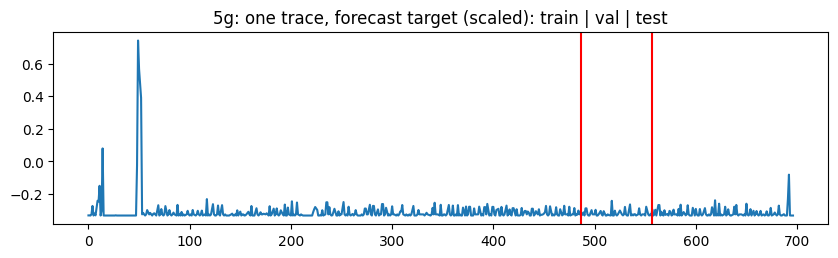


4g: train mean [ 0. -0. -0.  0. -0.]  std [1. 1. 1. 1. 1.]  (should be about 0 and 1)
window shapes: (661, 12, 5) (661,)


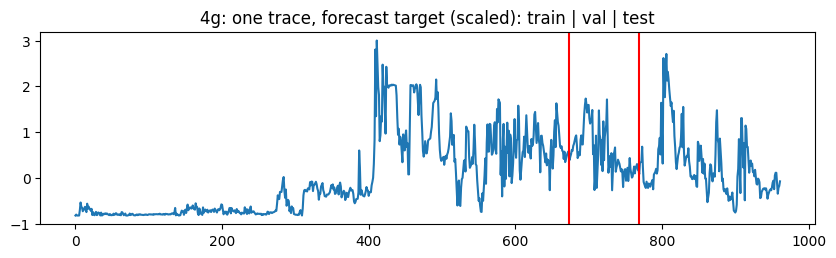


4g_full: train mean [-0. -0.  0.  0.  0.  0.  0.]  std [1. 1. 1. 1. 1. 1. 1.]  (should be about 0 and 1)
window shapes: (661, 12, 7) (661,)


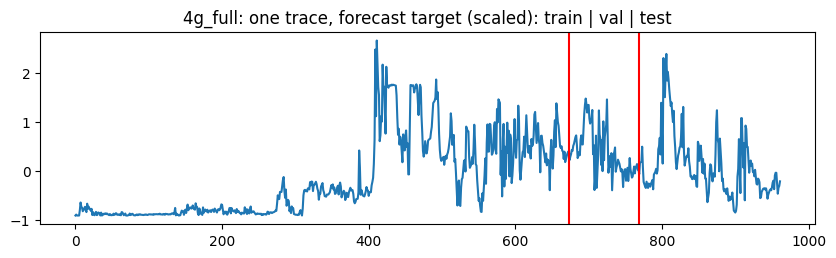


operator: train mean [-0.]  std [1.]  (should be about 0 and 1)
window shapes: (7504, 12, 3) (7504,)


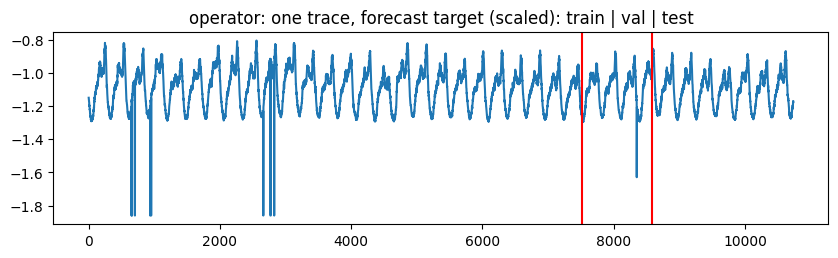

In [6]:
report = pd.DataFrame([dict(dataset=n, traces=len(s), total_steps=s.steps.sum(),
                            train=s.train.sum(), val=s.val.sum(), test=s.test.sum())
                       for n, s in SUMM.items()])
print(report.to_string(index=False))
report.to_csv(f"{ROOT}/processed/dataset_summary.csv", index=False)   # table for the report

for name in SUMM:
    fs = sorted(glob.glob(f"{ROOT}/processed/{name}/*.npz"))
    cols = slice(0, 1) if name == "operator" else slice(None)   # operator: only the value column is scaled
    tr = np.vstack([np.load(f)["train"] for f in fs])[:, cols]
    print(f"\n{name}: train mean {tr.mean(0).round(2)}  std {tr.std(0).round(2)}  (should be about 0 and 1)")
    z = np.load(fs[0])
    X, y = make_windows(z["train"])
    print("window shapes:", X.shape, y.shape)
    series = np.concatenate([z["train"][:, 0], z["val"][:, 0], z["test"][:, 0]])
    n1 = len(z["train"]); n2 = n1 + len(z["val"])
    plt.figure(figsize=(10, 2.5)); plt.plot(series)
    plt.axvline(n1, c="r"); plt.axvline(n2, c="r")
    plt.title(f"{name}: one trace, forecast target (scaled): train | val | test"); plt.show()

In [7]:
import hashlib
for ds in ["5g", "4g", "operator"]:
    h = {}
    for f in sorted(glob.glob(f"{ROOT}/processed/{ds}/*.npz")):
        z = np.load(f)
        k = hashlib.md5(np.round(z["train"][:, 0], 4).tobytes()).hexdigest()
        h.setdefault(k, []).append(os.path.basename(f)[:-4])
    dups = [v for v in h.values() if len(v) > 1]
    print(f"{ds}: {sum(len(v) for v in h.values())} traces | unique {len(h)} | groups of copies: {len(dups)}")
    for v in dups: print("   same data:", v)

5g: 79 traces | unique 79 | groups of copies: 0
4g: 134 traces | unique 134 | groups of copies: 0
operator: 55 traces | unique 55 | groups of copies: 0
